## 2. Deep Learning Foundations

### Neural Network Exercises

### 1. Build a simple neural network from scratch with NumPy.

In [3]:
import numpy as np

# I/O
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

# Initialize weights and biases
np.random.seed(1)
W1 = np.random.randn(2, 4)
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1)
b2 = np.zeros((1, 1))

def sigmoid(x):
    return 1 / (1+np.exp(-x))

for _ in range(10000):
    # Forward Pass
    hidden = sigmoid(X @ W1 + b1)
    output = sigmoid(hidden @ W2 + b2)

    # Calculate errors and gradients
    output_error = output - y
    hidden_error = (output_error @ W2.T) * hidden * (1-hidden)

    # Update weights and biases
    W2 -= 0.5 * (hidden.T @ output_error) / len(X)
    b2 -= 0.5 * output_error.mean(axis=0)
    W1 -= 0.5 * (X.T @ hidden_error) / len(X)
    b1 -= 0.5 * hidden_error.mean(axis=0)

print((output >= 0.5).astype(int))


[[0]
 [1]
 [1]
 [0]]


### 2. Implement and visualize Sigmoid, Tanh, ReLU, Leaky ReLU, and Softmax activation functions.

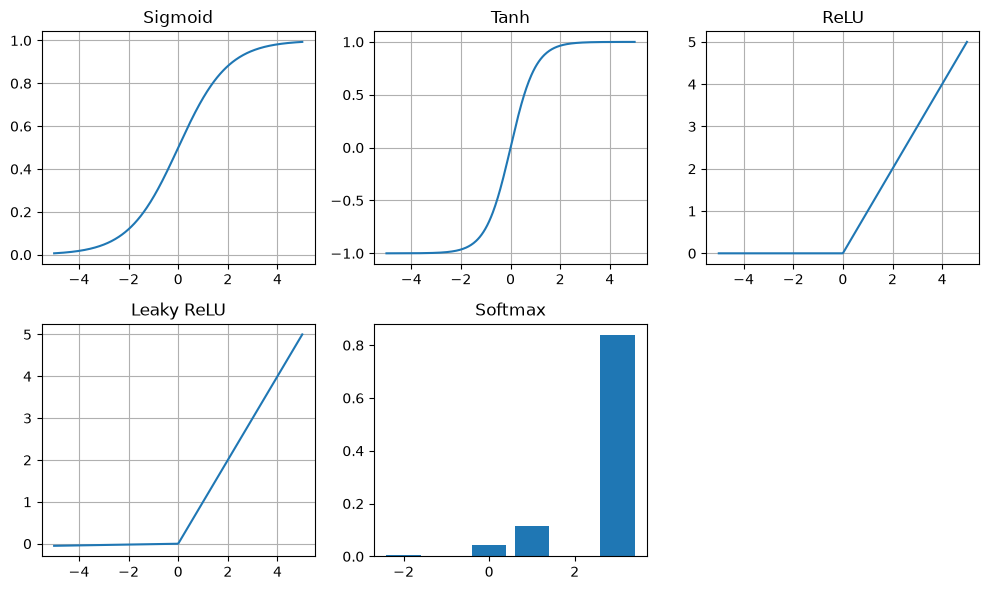

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 

x = np.linspace(-5, 5, 400)

sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)
leaky_relu = np.maximum(0.01 * x, x)

z = np.array([-2, 0, 1, 3])
softmax = np.exp(z - z.max()) / np.exp(z - z.max()).sum()

fig, ax = plt.subplots(2, 3, figsize=(10, 6))

for a, y, name in zip(ax.flat[:4], [sigmoid, tanh, relu, leaky_relu], ["Sigmoid", "Tanh", "ReLU", "Leaky ReLU"]):
    a.plot(x, y)
    a.set_title(name)
    a.grid()

ax.flat[4].bar(z, softmax)
ax.flat[4].set_title("Softmax")
ax.flat[5].axis("off")
plt.tight_layout()
plt.show()